# Fixed-cohort sensitivity of sea-level estimates
Run cells in order. Start with the station counts, then compute the estimates and endpoint changes.

This compares the **original selection**, **Stage 1 fixed cohort**, and **fully selected fixed cohort** over the final five 70-year windows (1946–2015 through 1950–2019). It uses actual station slopes, not simulations.

The fastest route reuses `all_station_decisions.csv` from the HAC notebook. No shared kernel is needed. Raw annual data can also be used. Defaults match your completed HAC run: 87% completeness, two-sided $p\le0.01$, BH $q=0.01$, and 1000 half-samples. Requires NumPy, SciPy, pandas and Matplotlib.


## 1. Paths and settings
Set `CSV_PATH` to the full path of the **all_station_decisions.csv** saved by Section 9 of the HAC notebook. Keep it next to that export's `metadata.json` when possible. The file must include **all eligible stations**, not just selected stations.

Use `INPUT_MODE='raw'` to recompute from `DATA_DIR`. For raw mode, change completeness to 0.75 to check the original 25%-missing-data result, or set window length to 60 for the other figure panel. CSV mode requires a matching export for each completeness/length/bandwidth combination.

`comparison_end_years=[2015,2019]` includes every annual window ending in this interval. Changing this range changes the intersections defining the fixed cohorts. Do not choose the range from the result you prefer.


In [8]:
from pathlib import Path
from datetime import datetime
import os, glob, json, hashlib
import numpy as np
import scipy
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

INPUT_MODE = 'csv'                  # 'csv' or 'raw'
CSV_PATH = Path('./observational_hac_results/export_20261124_192419_149811/all_station_decisions.csv')
DATA_DIR = Path('../data/rlr_annual')
OUTPUT_DIR = Path('fixed_cohort_results')
CONFIG = dict(window_length=70, completeness=0.87,
              comparison_end_years=[2015,2019],
              pcrit=0.01, fdr_q=0.01, hac_lag=3,
              methods=['OLS','HAC','HAC_BH'],
              gammas=[0.0,0.10,0.25], sample_fraction=0.5,
              repetitions=1000, seed=2027)
PLOT_METHOD = 'OLS'
PLOT_GAMMA = 0.25
print(CONFIG)
print('CSV path:', CSV_PATH.resolve())


{'window_length': 70, 'completeness': 0.87, 'comparison_end_years': [2015, 2019], 'pcrit': 0.01, 'fdr_q': 0.01, 'hac_lag': 3, 'methods': ['OLS', 'HAC', 'HAC_BH'], 'gammas': [0.0, 0.1, 0.25], 'sample_fraction': 0.5, 'repetitions': 1000, 'seed': 2027}
CSV path: C:\Users\User\work\IPGP\Climate\bin\observational_hac_results\export_20261124_192419_149811\all_station_decisions.csv


## 2. Cohort definitions
Let $E_j$ be all completeness-qualified stations in window $j$, and $S_j$ the stations with significantly positive fitted slopes under the chosen inference method.

| Curve | Stations used before trimming |
|---|---|
| Original selection | $S_j$ |
| Stage 1 fixed cohort | $S_j\cap E_*$, where $E_*=\bigcap_j E_j$ |
| Fully selected fixed cohort | $S_*=\bigcap_j S_j$ |

Stage 1 fixes availability but keeps per-window significance selection. Its selected membership can change. The fully selected cohort has the same stations **before trimming** in every window; fitted slopes are always the slopes for the respective window, not full-record drifts.

Upper-tail trimming is repeated independently in each window, so retained identities after trimming can change even in the fully selected cohort. The notebook exports this turnover and includes $\gamma=0$ for context. The fixed cohort is defined before trimming, following the reviewer's proposal.

OLS, HAC and HAC+BH each use their own selected-set intersection. BH p-values are adjusted over the complete $E_j$ family **before** restricting to either cohort. This retains the previous per-window selection decisions and isolates cohort restriction. BH is not recomputed on the smaller intersection.

The comparisons quantify sensitivity, not an additive causal decomposition of changes in the nonlinear estimator. A fully selected cohort is a retrospective, persistently selected subset; it is not a geographically representative population.


## 3. Functions (run once)
The previous reader, completeness rules, OLS/HAC calculation and median-of-subsample-medians estimator are embedded. HAC uses Bartlett calendar-year lags, finite-sample multiplier $n/(n-2)$, and approximate $t_{n-2}$ p-values. Gaps are not compressed. BH uses the same two-sided p-values as the HAC notebook.

Raw mode preserves the earlier treatment of quality flags (read but not used to exclude records). The station record must span each complete window. MATLAB rounding for positive numbers is preserved. The seed convention matches the HAC notebook; identical selected slopes give identical estimates within a window.

`subsample_sd` is a conditional resampling standard deviation, not a confidence interval for an endpoint difference.


In [2]:
import os
import glob
import numpy as np


def read_annual(directory_name):
    """
    Reads PSMSL RLR annual data directory.
    
    Parameters:
        directory_name (str): Path to unzipped PSMSL directory containing 
                              'filelist.txt' and the 'data/' folder.
                              
    Returns:
        list of dict: Each dict corresponds to a station with keys:
            'id', 'latitude', 'longitude', 'name', 'coastline',
            'stationcode', 'stationflag', 'year', 'height',
            'interpolated', 'isMtl', 'dataflag'
    """
    if not os.path.isdir(directory_name):
        raise FileNotFoundError(f"Cannot find directory: {directory_name}")

    data_dir = os.path.join(directory_name, 'data')
    if not os.path.isdir(data_dir):
        raise FileNotFoundError(
            f"Cannot find data directory {data_dir}. "
            "Please ensure the path points to the root unzipped folder, not 'data/' itself."
        )

    # 1. Parse filelist.txt catalogue
    cat_file = os.path.join(directory_name, 'filelist.txt')
    if not os.path.isfile(cat_file):
        raise FileNotFoundError(f"Could not find catalogue file: {cat_file}")

    catalogue = {}
    with open(cat_file, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split(';')
            if len(parts) < 7:
                continue
            st_id = int(parts[0].strip())
            catalogue[st_id] = {
                'latitude': float(parts[1].strip()),
                'longitude': float(parts[2].strip()),
                'name': parts[3].strip(),
                'coastline': int(parts[4].strip()) if parts[4].strip() else None,
                'stationcode': int(parts[5].strip()) if parts[5].strip() else None,
                'stationflag': parts[6].strip() == 'Y'
            }

    # 2. Match .rlrdata files
    file_paths = glob.glob(os.path.join(data_dir, '*.rlrdata'))
    data = []

    for path in sorted(file_paths):
        filename = os.path.basename(path)
        st_id = int(filename.split('.')[0])
        
        meta = catalogue.get(st_id, {
            'latitude': np.nan, 'longitude': np.nan, 'name': '',
            'coastline': None, 'stationcode': None, 'stationflag': False
        })

        # 3. Read station time series
        # Format: Year; Height; InterpolatedFlag; QualityFlags(3 digits)
        years, heights, interpolated, is_mtl, dataflag = [], [], [], [], []
        
        with open(path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(';')
                if len(parts) < 4:
                    continue

                yr = int(parts[0].strip())
                raw_h = float(parts[1].strip())
                h = np.nan if raw_h == -99999 else raw_h
                interp = parts[2].strip() == 'Y'

                # Flags: 3-character string (e.g. "000")
                flags_str = parts[3].strip()
                flags_str = flags_str.ljust(3, '0')
                mtl = flags_str[1] == '1'
                dflag = flags_str[2] == '1'

                years.append(yr)
                heights.append(h)
                interpolated.append(interp)
                is_mtl.append(mtl)
                dataflag.append(dflag)

        station_record = {
            'id': st_id,
            'latitude': meta['latitude'],
            'longitude': meta['longitude'],
            'name': meta['name'],
            'coastline': meta['coastline'],
            'stationcode': meta['stationcode'],
            'stationflag': meta['stationflag'],
            'year': np.array(years, dtype=int),
            'height': np.array(heights, dtype=float),
            'interpolated': np.array(interpolated, dtype=bool),
            'isMtl': np.array(is_mtl, dtype=bool),
            'dataflag': np.array(dataflag, dtype=bool)
        }
        data.append(station_record)

    return data


In [3]:
def matlab_round_positive(x):
    """MATLAB-style rounding for non-negative numbers."""
    return int(np.floor(x + 0.5))

def estimate_trimmed_median(
    slopes,
    gamma=0.25,
    sample_fraction=0.5,
    repetitions=1000,
    seed=0,
):
    """
    Compute M' from slopes already passing station selection.

    Steps:
      1. Sort the slopes.
      2. Retain round((1 - gamma) * N) smallest slopes.
      3. Draw random subsamples without replacement.
      4. Compute the median of each subsample.
      5. Return the median of those medians.

    Separate draws are independent; the same subset may recur.
    Legacy error bars are not calculated here.
    """
    slopes = np.asarray(slopes, dtype=float)

    if slopes.ndim != 1 or slopes.size == 0:
        raise ValueError("slopes must be a nonempty one-dimensional array.")
    if not np.all(np.isfinite(slopes)):
        raise ValueError("slopes must contain only finite values.")
    if not 0 <= gamma < 1:
        raise ValueError("gamma must satisfy 0 <= gamma < 1.")
    if not 0 < sample_fraction <= 1:
        raise ValueError("sample_fraction must satisfy 0 < value <= 1.")
    if not isinstance(repetitions, (int, np.integer)) or repetitions < 1:
        raise ValueError("repetitions must be a positive integer.")

    sorted_slopes = np.sort(slopes)
    n_original = sorted_slopes.size

    n_retained = matlab_round_positive((1 - gamma) * n_original)
    if n_retained < 1:
        raise ValueError("The trimming fraction leaves no slopes.")

    retained = sorted_slopes[:n_retained]
    removed = sorted_slopes[n_retained:]

    sample_size = matlab_round_positive(sample_fraction * n_retained)
    if sample_size < 1:
        raise ValueError("The subsample size is zero.")

    rng = np.random.default_rng(seed)
    indices = np.array([rng.choice(n_retained, size=sample_size, replace=False)
                        for _ in range(repetitions)])
    subsample_medians = np.median(retained[indices], axis=1)

    return {
        "M_prime": float(np.median(subsample_medians)),
        "median_original": float(np.median(sorted_slopes)),
        "median_retained": float(np.median(retained)),
        "n_original": n_original,
        "n_retained": n_retained,
        "sample_size": sample_size,
        "retained_slopes": retained.copy(),
        "removed_slopes": removed.copy(),
        "subsample_medians": subsample_medians,
    }


In [4]:
def adjusted_bh(p):
    """BH adjustment across the entire completeness-qualified station family."""
    p = np.asarray(p, float)
    if not np.all(np.isfinite(p)) or np.any((p < 0) | (p > 1)):
        raise ValueError('Invalid p-values')
    if not len(p): return p.copy()
    order = np.argsort(p, kind='stable')
    q = np.minimum.accumulate((p[order] * len(p) / np.arange(1, len(p)+1))[::-1])[::-1]
    out = np.empty_like(p)
    out[order] = np.minimum(q, 1.)
    return out

def regression_hac(years, heights, bandwidth=3):
    """OLS and calendar-lag Bartlett HAC. t(n-2) inference is approximate for HAC."""
    years, heights = np.asarray(years, int), np.asarray(heights, float)
    valid = np.isfinite(heights) & (heights != -99999)
    t, y = years[valid], heights[valid]
    n = len(y)
    if n < 3 or np.any(np.diff(t) <= 0):
        raise ValueError('Need at least three observations in increasing distinct years')
    L = int(bandwidth)
    if L < 0 or L != bandwidth or L >= years[-1]-years[0]+1:
        raise ValueError('Invalid HAC bandwidth')
    x = t - t.mean()
    X = np.column_stack([np.ones(n), x])
    bread = np.linalg.inv(X.T @ X)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    cov_ols = bread * (e @ e) / (n-2)
    # Zero scores at absent years; no interpolation and no compression of gaps.
    scores = np.zeros((int(years[-1]-years[0]+1), 2))
    scores[t-years[0]] = X * e[:, None]
    meat = scores.T @ scores
    for lag in range(1, L+1):
        cross = scores[lag:].T @ scores[:-lag]
        meat += (1-lag/(L+1)) * (cross + cross.T)
    cov_hac = (n/(n-2)) * bread @ meat @ bread
    def infer(var):
        se = np.sqrt(max(0., var))
        if se == 0:
            p = 1. if beta[1] == 0 else 0.
        else:
            p = float(2*stats.t.sf(abs(beta[1]/se), df=n-2))
        return se, p
    se_o, p_o = infer(cov_ols[1,1])
    se_h, p_h = infer(cov_hac[1,1])
    pairs = np.where(np.diff(t) == 1)[0]
    rho = np.nan
    if len(pairs) >= 3 and np.std(e[pairs]) > 0 and np.std(e[pairs+1]) > 0:
        rho = float(np.corrcoef(e[pairs], e[pairs+1])[0,1])
    return dict(slope=float(beta[1]), n_obs=n, se_ols=se_o, p_ols=p_o,
                se_hac=se_h, p_hac=p_h, hac_lag=L, residual_rho1=rho,
                n_adjacent_pairs=len(pairs))

def station_frame(series, start, length, completeness, bandwidth):
    rows = []
    end = start+length-1
    years = np.arange(start, end+1)
    for i, st in enumerate(series):
        sy, h = np.asarray(st['year'], int), np.asarray(st['height'], float)
        if not len(sy): continue
        if len(sy) != len(h) or np.any(np.diff(sy) <= 0):
            raise ValueError(f'Invalid years/heights at station {st["id"]}')
        if sy[0] > start or sy[-1] < end: continue
        chunk = np.full(length, np.nan)
        inside = (sy >= start) & (sy <= end)
        chunk[sy[inside]-start] = h[inside]
        n = int((np.isfinite(chunk) & (chunk != -99999)).sum())
        if n/length < completeness: continue
        row = regression_hac(years, chunk, bandwidth)
        row.update(station_id=st['id'], name=st.get('name',''), station_index=i,
                   start_year=start, end_year=end, window_label=start+length/2,
                   n_missing=length-n)
        rows.append(row)
    columns = ['slope','n_obs','se_ols','p_ols','se_hac','p_hac','hac_lag',
               'residual_rho1','n_adjacent_pairs','station_id','name','station_index',
               'start_year','end_year','window_label','n_missing']
    return pd.DataFrame(rows, columns=columns)

def select_methods(frame, pcrit, fdr_q):
    d = frame.copy()
    d['p_hac_bh'] = adjusted_bh(d['p_hac'])
    positive = d['slope'] > 0
    d['OLS'] = positive & (d['p_ols'] <= pcrit)
    d['HAC'] = positive & (d['p_hac'] <= pcrit)
    d['HAC_BH'] = positive & (d['p_hac_bh'] <= fdr_q)
    return d

def data_fingerprint(series):
    h = hashlib.sha256()
    for st in series:
        h.update(str(st['id']).encode())
        h.update(np.asarray(st['year'], dtype='<i8').tobytes())
        h.update(np.asarray(st['height'], dtype='<f8').tobytes())
    return h.hexdigest()


In [5]:
COHORT_LABELS = {
    'variable': 'Original selection',
    'stage1_fixed': 'Stage 1 fixed cohort',
    'fully_fixed': 'Fully selected fixed cohort',
}


def validate_config(cfg):
    if cfg['window_length'] < 3: raise ValueError('Window length must be at least 3.')
    ends=cfg['comparison_end_years']
    if len(ends)!=2 or ends[0]>=ends[1]:
        raise ValueError('Provide an inclusive range of at least two window end years.')
    if not 0<cfg['completeness']<=1: raise ValueError('Invalid completeness fraction.')
    if not 0<cfg['pcrit']<1 or not 0<cfg['fdr_q']<1: raise ValueError('Invalid p/q threshold.')
    if not set(cfg['methods']).issubset({'OLS','HAC','HAC_BH'}) or not cfg['methods']:
        raise ValueError('Unknown selection method.')
    if len(set(cfg['methods']))!=len(cfg['methods']): raise ValueError('Duplicate methods.')
    if not cfg['gammas'] or any(not 0<=g<1 for g in cfg['gammas']): raise ValueError('Invalid trimming fractions.')
    if len(set(cfg['gammas']))!=len(cfg['gammas']): raise ValueError('Duplicate trimming fractions.')
    return np.arange(ends[0], ends[1]+1)-cfg['window_length']+1


def prepare_decisions(frame, cfg):
    """Validate complete per-window eligible tables; recompute selection before restricting cohorts."""
    starts=validate_config(cfg)
    required=['station_id','start_year','end_year','n_obs','n_missing','slope',
              'p_ols','p_hac','hac_lag']
    absent=set(required)-set(frame.columns)
    if absent: raise ValueError(f'Missing columns: {sorted(absent)}')
    d=frame[frame.start_year.isin(starts)].copy()
    if set(d.start_year)!=set(starts):
        raise ValueError('CSV must contain all requested windows and every eligible station, including unselected stations.')
    d['station_id']=d.station_id.astype(str)
    if d.station_id.isna().any() or d.duplicated(['start_year','station_id']).any():
        raise ValueError('Missing or duplicate station identities.')
    if not np.all(d.end_year-d.start_year+1==cfg['window_length']): raise ValueError('Window length mismatch.')
    if not np.all(d.n_obs+d.n_missing==cfg['window_length']): raise ValueError('Invalid observation counts.')
    if not np.all(d.n_obs>=np.ceil(cfg['completeness']*cfg['window_length'])):
        raise ValueError('CSV contains stations below the configured completeness threshold; use a matching export or raw mode.')
    if not np.all(d.hac_lag==cfg['hac_lag']): raise ValueError('HAC bandwidth mismatch; use a matching export or raw mode.')
    if not np.isfinite(d[['slope','p_ols','p_hac']].to_numpy(float)).all(): raise ValueError('Nonfinite inference results.')
    if ((d[['p_ols','p_hac']]<0)|(d[['p_ols','p_hac']]>1)).any().any(): raise ValueError('Invalid p-values.')
    if 'name' not in d: d['name']=''
    d['window_label']=d.start_year+cfg['window_length']/2
    tables=[]
    for _, group in d.groupby('start_year', sort=True):
        tables.append(select_methods(group,cfg['pcrit'],cfg['fdr_q']))
    return pd.concat(tables,ignore_index=True).sort_values(['start_year','station_id']).reset_index(drop=True)


def load_decisions_csv(path, cfg):
    path=Path(path)
    if not path.exists(): raise FileNotFoundError(f'Set CSV_PATH to the previous all_station_decisions.csv: {path}')
    meta_path=path.with_name('metadata.json')
    provenance=dict(input_mode='csv',input_path=str(path.resolve()),
                    sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    if meta_path.exists():
        meta=json.loads(meta_path.read_text(encoding='utf-8'))
        old=meta.get('config',{})
        for key in ['window_length','completeness','hac_lag']:
            if key not in old or old[key]!=cfg[key]:
                raise ValueError(f'CSV metadata mismatch for {key}; use a matching export or raw mode.')
        provenance['input_metadata']=meta
        print('Source configuration checked against metadata.json.')
    else:
        print('No accompanying metadata.json. Use the export made with the configured completeness, length and HAC lag.')
        print('Counts and lag are checked below; the CSV alone cannot certify that the eligible station list is exhaustive.')
        provenance['input_metadata']=None
    frame=pd.read_csv(path,dtype={'station_id':str})
    if frame.station_id.isna().any(): raise ValueError('Missing station ID in CSV.')
    return prepare_decisions(frame,cfg), provenance


def fit_requested_windows(series,cfg):
    frames=[]
    for start in validate_config(cfg):
        f=station_frame(series,int(start),cfg['window_length'],cfg['completeness'],cfg['hac_lag'])
        frames.append(f)
        print(f'{start}–{start+cfg["window_length"]-1}: {len(f)} eligible')
    provenance=dict(input_mode='raw',data_sha256=data_fingerprint(series))
    return prepare_decisions(pd.concat(frames,ignore_index=True),cfg),provenance


def define_cohorts(decisions,cfg):
    starts=validate_config(cfg)
    eligible={int(s):set(decisions.loc[decisions.start_year==s,'station_id']) for s in starts}
    common_eligible=set.intersection(*eligible.values())
    selected={}
    fixed={}
    for method in cfg['methods']:
        selected[method]={int(s):set(decisions.loc[(decisions.start_year==s)&decisions[method],'station_id']) for s in starts}
        fixed[method]=set.intersection(*selected[method].values())
        assert fixed[method]<=common_eligible
    universe=sorted(set.union(*eligible.values()))
    names=decisions.drop_duplicates('station_id').set_index('station_id')['name']
    membership=pd.DataFrame({'station_id':universe})
    membership['name']=membership.station_id.map(names)
    membership['stage1_fixed']=membership.station_id.isin(common_eligible)
    for method in cfg['methods']:
        membership[f'fully_fixed_{method}']=membership.station_id.isin(fixed[method])
    rows=[]
    for method in cfg['methods']:
        for start in starts:
            rows.append(dict(method=method,start_year=int(start),end_year=int(start+cfg['window_length']-1),
               eligible=len(eligible[start]),original_selected=len(selected[method][start]),
               stage1_fixed_eligible=len(common_eligible),
               stage1_fixed_selected=len(common_eligible & selected[method][start]),
               fully_fixed_selected=len(fixed[method])))
    return dict(eligible=eligible,common_eligible=common_eligible,selected=selected,fixed=fixed),membership,pd.DataFrame(rows)


def analyze_cohorts(decisions,cohorts,cfg):
    rows=[]; audit=[]
    for method in cfg['methods']:
        for start in validate_config(cfg):
            frame=decisions[decisions.start_year==start].copy()
            original=cohorts['selected'][method][start]
            sets={'variable':original,
                  'stage1_fixed':original & cohorts['common_eligible'],
                  'fully_fixed':cohorts['fixed'][method]}
            for cohort,ids in sets.items():
                chosen=frame[frame.station_id.isin(ids)].sort_values(['slope','station_id'],kind='stable')
                for gamma in cfg['gammas']:
                    row=dict(method=method,cohort=cohort,start_year=int(start),
                        end_year=int(start+cfg['window_length']-1),window_label=start+cfg['window_length']/2,
                        gamma=gamma,eligible_original=len(frame),n_selected=len(chosen),
                        n_retained=0,sample_size=0,median_selected=np.nan,median_retained=np.nan,
                        mean_selected=np.nan,M_prime=np.nan,subsample_sd=np.nan)
                    retained_ids=set()
                    if len(chosen):
                        seed=np.random.SeedSequence([cfg['seed'],int(start),cfg['window_length'],int(round(gamma*1000000))])
                        z=estimate_trimmed_median(chosen.slope.to_numpy(float),gamma=gamma,
                            sample_fraction=cfg['sample_fraction'],repetitions=cfg['repetitions'],seed=seed)
                        for key in ['n_retained','sample_size','median_retained','M_prime']: row[key]=z[key]
                        row.update(median_selected=float(chosen.slope.median()),mean_selected=float(chosen.slope.mean()),
                                   subsample_sd=float(np.std(z['subsample_medians'],ddof=1)))
                        retained_ids=set(chosen.iloc[:z['n_retained']].station_id)
                    rows.append(row)
                    for r in chosen.itertuples():
                        audit.append(dict(method=method,cohort=cohort,start_year=int(start),end_year=row['end_year'],
                                          gamma=gamma,station_id=r.station_id,name=r.name,slope=r.slope,
                                          retained_after_trimming=r.station_id in retained_ids))
    summary=pd.DataFrame(rows)
    reference=summary[summary.cohort=='variable'][['method','start_year','gamma','M_prime']].rename(columns={'M_prime':'M_original'})
    summary=summary.merge(reference,on=['method','start_year','gamma'],validate='many_to_one')
    summary['delta_vs_original']=summary.M_prime-summary.M_original
    audit=pd.DataFrame(audit,columns=['method','cohort','start_year','end_year','gamma','station_id','name','slope','retained_after_trimming'])
    turnover=[]
    for (method,cohort,gamma),g in summary.groupby(['method','cohort','gamma'],sort=False):
        previous_pre=previous_post=None
        for r in g.sort_values('start_year').itertuples():
            a=audit[(audit.method==method)&(audit.cohort==cohort)&(audit.gamma==gamma)&(audit.start_year==r.start_year)]
            pre=set(a.station_id);post=set(a.loc[a.retained_after_trimming.astype(bool),'station_id'])
            turnover.append(dict(method=method,cohort=cohort,gamma=gamma,start_year=r.start_year,
                gained_before_trimming=np.nan if previous_pre is None else len(pre-previous_pre),
                lost_before_trimming=np.nan if previous_pre is None else len(previous_pre-pre),
                gained_after_trimming=np.nan if previous_post is None else len(post-previous_post),
                lost_after_trimming=np.nan if previous_post is None else len(previous_post-post)))
            previous_pre,previous_post=pre,post
    summary=summary.merge(pd.DataFrame(turnover),on=['method','cohort','gamma','start_year'],validate='one_to_one')
    return summary,audit


def endpoint_changes(summary):
    out=[]
    for (method,cohort,gamma),g in summary.groupby(['method','cohort','gamma'],sort=False):
        g=g.sort_values('end_year')
        last=g.iloc[-1]
        # First endpoint and the final one- and two-step changes.
        refs=sorted(set([int(g.iloc[0].end_year),int(g.iloc[-2].end_year)]+([int(g.iloc[-3].end_year)] if len(g)>2 else [])))
        for end in refs:
            first=g[g.end_year==end].iloc[0]
            out.append(dict(method=method,cohort=cohort,gamma=gamma,
                reference_end_year=end,final_end_year=int(last.end_year),
                M_reference=first.M_prime,M_final=last.M_prime,
                change=last.M_prime-first.M_prime,
                change_median_retained=last.median_retained-first.median_retained,
                n_reference=int(first.n_selected),n_final=int(last.n_selected)))
    return pd.DataFrame(out)


def plot_cohorts(summary,method='OLS',gamma=.25):
    d=summary[(summary.method==method)&np.isclose(summary.gamma,gamma)]
    if d.empty: raise ValueError('Requested method/gamma was not computed.')
    fig,axes=plt.subplots(1,3,figsize=(14,4.2),layout='constrained')
    for cohort,g in d.groupby('cohort',sort=False):
        g=g.sort_values('end_year');label=COHORT_LABELS[cohort]
        axes[0].plot(g.end_year,g.M_prime,'o-',label=label)
        axes[1].plot(g.end_year,g.n_selected,'o-',label=label)
        axes[2].plot(g.end_year,g.M_prime-g.M_prime.iloc[0],'o-',label=label)
    for i,ax in enumerate(axes):
        ax.set_xlabel('Window end year');ax.grid(ls=':',alpha=.5)
        ax.set_title(f'({chr(97+i)})',loc='left')
        if d.end_year.nunique()<=12: ax.set_xticks(sorted(d.end_year.unique()))
    axes[0].set_ylabel("Trimmed estimate $M'$, mm/yr")
    axes[1].set_ylabel('Selected stations before trimming')
    axes[2].set_ylabel("Change from first window, mm/yr")
    axes[2].axhline(0,color='black',lw=1,ls=':')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{method} selection; trimming fraction = {gamma:g}')
    return fig


def verify_invariants(summary,audit,cohorts,cfg):
    for method in cfg['methods']:
        f=summary[(summary.method==method)&(summary.cohort=='fully_fixed')]
        assert (f.n_selected==len(cohorts['fixed'][method])).all()
        for start in validate_config(cfg):
            for gamma in cfg['gammas']:
                a=audit[(audit.method==method)&(audit.start_year==start)&(audit.gamma==gamma)]
                assert set(a.loc[a.cohort=='fully_fixed','station_id'])==cohorts['fixed'][method]
                assert set(a.loc[a.cohort=='stage1_fixed','station_id'])<=cohorts['common_eligible']
    for r in summary.itertuples():
        if r.n_selected:
            assert r.n_retained==matlab_round_positive((1-r.gamma)*r.n_selected)
            assert r.sample_size==matlab_round_positive(cfg['sample_fraction']*r.n_retained)
        else: assert np.isnan(r.M_prime)
    return True


## 4. Quick checks
These verify intersection logic and the estimator on small examples without loading empirical files.


In [6]:
toy_cfg=CONFIG.copy()
toy_cfg.update(comparison_end_years=[2000,2002],methods=['OLS'])
toy=[]
for end, ids, selected in [(2000,[1,2,3],[1,2]), (2001,[1,2,4],[1,2]), (2002,[1,2,5],[1,5])]:
    for sid in ids:
        toy.append(dict(station_id=str(sid),name=str(sid),start_year=end-69,
                        end_year=end,OLS=sid in selected))
toy_cohorts,toy_members,toy_counts=define_cohorts(pd.DataFrame(toy),toy_cfg)
assert toy_cohorts['common_eligible']=={'1','2'}
assert toy_cohorts['fixed']['OLS']=={'1'}
assert toy_counts.stage1_fixed_selected.tolist()==[2,2,1]
z=estimate_trimmed_median([1,1.2,1.4,1.6,1.8,2,6,10],gamma=.25)
assert z['n_retained']==6 and z['sample_size']==3 and z['median_retained']==1.5
print('Cohort-definition and estimator checks passed.')


Cohort-definition and estimator checks passed.


## 5. Load or fit the requested windows
CSV mode does not refit or simulate records. Selection is reconstructed from p-values over all eligible stations in each window. An available source metadata file is checked against completeness, window length and HAC bandwidth. Without it, use the known matching export; exhaustiveness of the eligible lists cannot be verified from row counts alone.


In [9]:
if INPUT_MODE == 'csv':
    decisions, provenance = load_decisions_csv(CSV_PATH,CONFIG)
elif INPUT_MODE == 'raw':
    series=read_annual(str(DATA_DIR))
    if not len(series): raise ValueError('No station records found.')
    decisions, provenance = fit_requested_windows(series,CONFIG)
else:
    raise ValueError("INPUT_MODE must be 'csv' or 'raw'.")
display(decisions.groupby(['start_year','end_year']).agg(
    eligible=('station_id','size'), OLS=('OLS','sum'),
    HAC=('HAC','sum'), HAC_BH=('HAC_BH','sum')))
print('Loaded',len(decisions),'station-window fits.')


Source configuration checked against metadata.json.


,,eligible,OLS,HAC,HAC_BH
start_year,end_year,,,,
1946,2015,122,84,80,79
1947,2016,126,90,85,85
1948,2017,129,91,88,88
1949,2018,119,84,81,81
1950,2019,112,75,74,74


Loaded 608 station-window fits.


## 6. Inspect the cohorts before estimating
This is the first useful output to share. It shows how much the cohort restrictions reduce the sample. A very small intersection indicates limited information for this comparison; the notebook reports undefined estimates for an empty cohort.


In [10]:
cohorts, membership, cohort_counts = define_cohorts(decisions,CONFIG)
display(cohort_counts)
print('Common Stage 1 stations:',len(cohorts['common_eligible']))
for method in CONFIG['methods']:
    print(method,'fully selected fixed cohort:',len(cohorts['fixed'][method]))
print('Station identities are in the membership table.')
display(membership.head(10))


,method,start_year,end_year,eligible,original_selected,stage1_fixed_eligible,stage1_fixed_selected,fully_fixed_selected
0,OLS,1946,2015,122,84,100,64,64
1,OLS,1947,2016,126,90,100,66,64
2,OLS,1948,2017,129,91,100,66,64
3,OLS,1949,2018,119,84,100,67,64
4,OLS,1950,2019,112,75,100,67,64
5,HAC,1946,2015,122,80,100,61,61
6,HAC,1947,2016,126,85,100,62,61
7,HAC,1948,2017,129,88,100,63,61
8,HAC,1949,2018,119,81,100,64,61
9,HAC,1950,2019,112,74,100,66,61


Common Stage 1 stations: 100
OLS fully selected fixed cohort: 64
HAC fully selected fixed cohort: 61
HAC_BH fully selected fixed cohort: 61
Station identities are in the membership table.


,station_id,name,stage1_fixed,fully_fixed_OLS,fully_fixed_HAC,fully_fixed_HAC_BH
0,1,BREST,True,True,True,True
1,10,SAN FRANCISCO,True,True,True,True
2,11,WARNEMUNDE 2,True,True,True,True
3,111,FREMANTLE,True,True,True,True
4,112,FERNANDINA BEACH,True,True,True,True
5,113,KORSOR,False,False,False,False
6,118,KLAIPEDA,False,False,False,False
7,119,HORNBAEK,False,False,False,False
8,12,NEW YORK (THE BATTERY),True,True,True,True
9,120,GEDSER,False,False,False,False


## 7. Compute the three estimates
This is the main calculation. It uses 1000 subsamples per window/method/cohort/trimming fraction, with no repeated synthetic simulations. For five windows it is much smaller than the earlier simulation runs.

Run the cell once. Outputs include pre- and post-trimming station identities and sample sizes. Inspect `median_retained`, a deterministic companion to the resampled estimate, when assessing small differences. Estimates use the existing window-specific random streams; finite resampling contributes some variability.


In [11]:
summary, station_audit = analyze_cohorts(decisions,cohorts,CONFIG)
assert verify_invariants(summary,station_audit,cohorts,CONFIG)
print('Fixed-membership and trimming checks passed.')
display(summary[(summary.method==PLOT_METHOD)&np.isclose(summary.gamma,PLOT_GAMMA)][
    ['end_year','cohort','n_selected','n_retained','M_prime',
     'median_retained','delta_vs_original','gained_after_trimming','lost_after_trimming']].round(6))


Fixed-membership and trimming checks passed.


,end_year,cohort,n_selected,n_retained,M_prime,median_retained,delta_vs_original,gained_after_trimming,lost_after_trimming
2,2015,variable,84,63,1.648739,1.636189,0.000000,NaN,NaN
5,2015,stage1_fixed,64,48,1.858536,1.858536,0.209796,NaN,NaN
8,2015,fully_fixed,64,48,1.858536,1.858536,0.209796,NaN,NaN
11,2016,variable,90,68,1.663720,1.663720,0.000000,5.0,0.0
14,2016,stage1_fixed,66,50,1.880266,1.845212,0.216546,2.0,0.0
17,2016,fully_fixed,64,48,1.889245,1.889245,0.225525,0.0,0.0
20,2017,variable,91,68,1.678701,1.678701,0.000000,1.0,1.0
23,2017,stage1_fixed,66,50,1.866521,1.860788,0.187820,1.0,1.0
26,2017,fully_fixed,64,48,1.864416,1.867282,0.185715,1.0,1.0
29,2018,variable,84,63,1.819071,1.844103,0.000000,3.0,8.0


## 8. Compare endpoint changes
`change` is the last estimate minus the estimate in the indicated reference window. By default the table compares 2019 against 2015, 2017 and 2018 (window end years), including the final two-window increase. `change_median_retained` gives the corresponding change in the deterministic trimmed-sample median.

If a cohort estimate is undefined, its difference remains NaN; no zero or last valid value is substituted. These are descriptive differences between overlapping windows, not independent observations or significance tests.


In [12]:
changes=endpoint_changes(summary)
display(changes[np.isclose(changes.gamma,.25)].round(6))


,method,cohort,gamma,reference_end_year,final_end_year,M_reference,M_final,change,change_median_retained,n_reference,n_final
6,OLS,variable,0.25,2015,2019,1.648739,1.926253,0.277514,0.290064,84,75
7,OLS,variable,0.25,2017,2019,1.678701,1.926253,0.247553,0.247553,91,75
8,OLS,variable,0.25,2018,2019,1.819071,1.926253,0.107182,0.082150,84,75
15,OLS,stage1_fixed,0.25,2015,2019,1.858536,1.815747,-0.042789,0.001914,64,67
16,OLS,stage1_fixed,0.25,2017,2019,1.866521,1.815747,-0.050774,-0.000338,66,67
17,OLS,stage1_fixed,0.25,2018,2019,1.860660,1.815747,-0.044913,0.074875,67,67
24,OLS,fully_fixed,0.25,2015,2019,1.858536,1.950830,0.092294,0.093811,64,64
25,OLS,fully_fixed,0.25,2017,2019,1.864416,1.950830,0.086414,0.085064,64,64
26,OLS,fully_fixed,0.25,2018,2019,1.903759,1.950830,0.047071,0.048588,64,64
33,HAC,variable,0.25,2015,2019,1.696856,1.952346,0.255490,0.253246,80,74


## 9. Plot
Choose `PLOT_METHOD` and `PLOT_GAMMA` here. Panel (c) subtracts the first estimate separately for each curve, comparing their temporal changes despite different absolute levels. The x-axis uses window end years to make the recent period clear. Counts in panel (b) are before trimming.


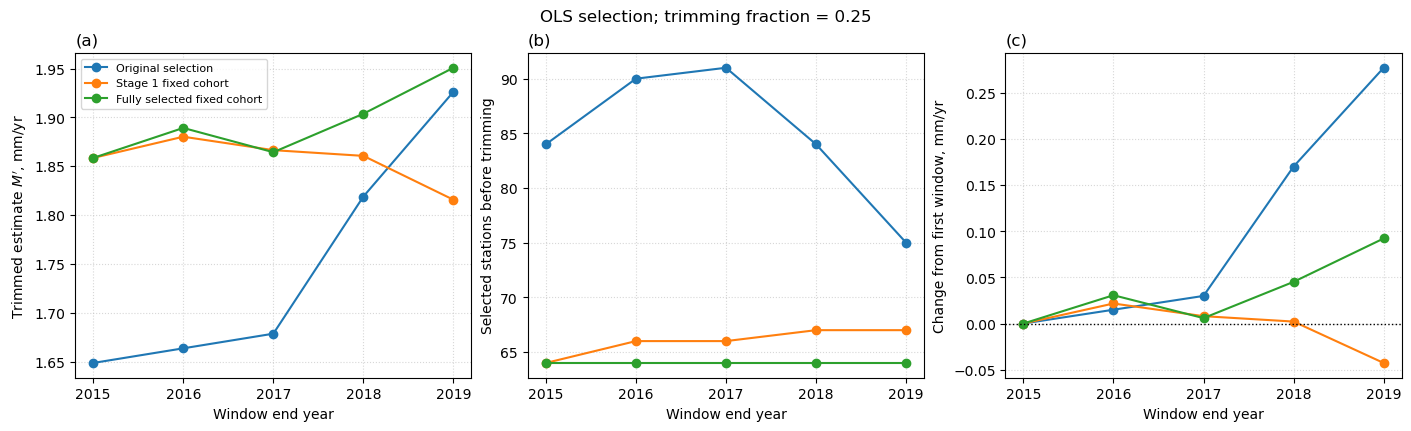

In [13]:
PLOT_METHOD = 'OLS'     # 'HAC' or 'HAC_BH' also available
PLOT_GAMMA = 0.25
fig = plot_cohorts(summary,method=PLOT_METHOD,gamma=PLOT_GAMMA)
plt.show()


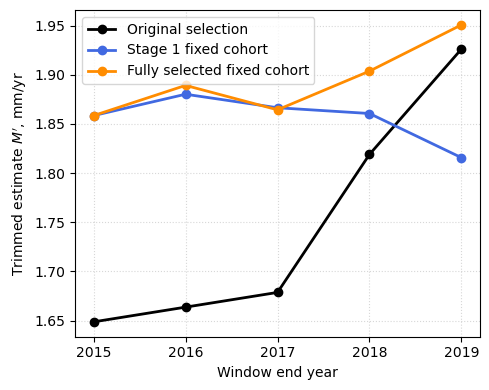

In [15]:
PLOT_METHOD = "OLS"       # Alternatively: "HAC" or "HAC_BH"
PLOT_GAMMA = 0.25

labels = {
    "variable": "Original selection",
    "stage1_fixed": "Stage 1 fixed cohort",
    "fully_fixed": "Fully selected fixed cohort",
}

colors = {
    "variable": "black",
    "stage1_fixed": "royalblue",
    "fully_fixed": "darkorange",
}

fig, ax = plt.subplots(figsize=(5, 4))

for cohort in labels:
    rows = summary[
        (summary["method"] == PLOT_METHOD)
        & (summary["cohort"] == cohort)
        & np.isclose(summary["gamma"], PLOT_GAMMA)
    ].sort_values("end_year")

    ax.plot(
        rows["end_year"],
        rows["M_prime"],
        marker="o",
        linewidth=2,
        color=colors[cohort],
        label=labels[cohort],
    )

ax.set_xlabel("Window end year")
ax.set_ylabel(r"Trimmed estimate $M'$, mm/yr")
ax.set_xticks(sorted(summary["end_year"].unique()))
ax.grid(linestyle=":", alpha=0.5)
ax.legend(frameon=True)
fig.tight_layout()

fig.savefig(
    f"fixed_cohort_trimmed_{PLOT_METHOD}.jpg",
    dpi=600,
    bbox_inches="tight",
)
plt.show()

## 10. Save results
A new export folder preserves each run. It contains configuration, source provenance, cohort counts and identities, all selected slopes with their trimming status, endpoint changes, and one JPG/PDF figure per inference method. Changing the period, completeness, or window length requires rerunning from Section 1.


In [16]:
export_dir=OUTPUT_DIR/('export_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
export_dir.mkdir(parents=True,exist_ok=False)
meta=dict(config=CONFIG,source=provenance,engine='fixed-cohort-v1',
          numpy=np.__version__,scipy=scipy.__version__,
          bh_family='all completeness-qualified stations within each window')
(export_dir/'metadata.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')
for name,table in [('cohort_counts',cohort_counts),('cohort_membership',membership),
                   ('station_decisions',decisions),('cohort_estimates',summary),
                   ('station_trimming_audit',station_audit),('endpoint_changes',changes)]:
    table.to_csv(export_dir/f'{name}.csv',index=False)
for method in CONFIG['methods']:
    saved_fig=plot_cohorts(summary,method=method,gamma=PLOT_GAMMA)
    saved_fig.savefig(export_dir/f'fixed_cohort_{method}.jpg',dpi=600,bbox_inches='tight')
    saved_fig.savefig(export_dir/f'fixed_cohort_{method}.pdf',bbox_inches='tight')
    plt.close(saved_fig)
print('Saved to:',export_dir.resolve())


Saved to: C:\Users\User\work\IPGP\Climate\bin\fixed_cohort_results\export_20261124_211648_783992


## 11. Interpretation and next comparisons
- Compare the original curve with Stage 1 fixed results to assess sensitivity to the availability restriction. Stage 2 membership can still change.
- Compare with the fully selected cohort to evaluate temporal changes for the same pre-trimming stations. Post-trimming identities and resampling can still change; inspect the audit and the untrimmed ($\gamma=0$) results.
- Report both cohort size and endpoint changes. A reduced increase suggests sensitivity to cohort choice; a persisting increase supports changes within this fixed set of fitted station trends. Neither pattern alone identifies a physical cause.
- The current completeness is **87%**, matching the recent HAC analysis. To examine the manuscript's main **75%-completeness** estimate directly, use raw mode with `completeness=0.75` or a matching CSV export. Use `window_length=60` for the other duration; keeping end years 2015–2019 then gives starts 1956–1960.
- Compare OLS and corrected selection using their explicitly reported cohorts. Their fully selected cohorts can differ.

No conclusion about the observed increase is assumed in this notebook. Share Section 6's cohort counts and Section 8's endpoint changes for interpretation.
